<a href="https://colab.research.google.com/github/Jasmipreethi/CN7031_Big_Data_Coursework/blob/main/BigData.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
#EDA of argo_2016-H1.parquet
#setup and download

!pip install -q pyspark huggingface_hub pyarrow matplotlib pandas

from huggingface_hub import hf_hub_download
from pyspark.sql import SparkSession, functions as F
import matplotlib.pyplot as plt


In [7]:
#starting the sparksession

spark = (SparkSession.builder.appName("argo_eda")
         .config("spark.driver.memory", "8g")
         .config("spark.sql.shuffle.partitions", "32")
         .getOrCreate())
#the 2016 first-half shard (344 MB)

path = hf_hub_download("taziksh/argo-profiles", "data/argo_2016-H1.parquet",
                       repo_type="dataset")

df = spark.read.parquet(path)

data/argo_2016-H1.parquet: reconstructing file:   0%|          |  0.00B /  344MB            

data/argo_2016-H1.parquet: downloading bytes:           |  0.00B            

In [22]:
#How big is the schema and size?

df.printSchema()
n_profiles = df.count()
print("profiles:", n_profiles)
print("floats :", df.select("platform_number").distinct().count())

root
 |-- profile_id: string (nullable = true)
 |-- platform_number: string (nullable = true)
 |-- cycle_number: integer (nullable = true)
 |-- direction: string (nullable = true)
 |-- data_mode: string (nullable = true)
 |-- dac: string (nullable = true)
 |-- time: timestamp (nullable = true)
 |-- juld_qc: string (nullable = true)
 |-- time_location: timestamp (nullable = true)
 |-- latitude: double (nullable = true)
 |-- longitude: double (nullable = true)
 |-- position_qc: string (nullable = true)
 |-- positioning_system: string (nullable = true)
 |-- ocean: string (nullable = true)
 |-- profile_pres_qc: string (nullable = true)
 |-- profile_temp_qc: string (nullable = true)
 |-- profile_psal_qc: string (nullable = true)
 |-- n_levels: integer (nullable = true)
 |-- pres: array (nullable = true)
 |    |-- element: float (containsNull = true)
 |-- pres_qc: array (nullable = true)
 |    |-- element: byte (containsNull = true)
 |-- pres_adjusted: array (nullable = true)
 |    |-- eleme

In [21]:
#Estimate the exploded size before exploding

total_levels = df.agg(F.sum("n_levels")).first()[0]
print("total levels if fully exploded:", total_levels)
print("avg levels per profile   :", round(total_levels / n_profiles, 1))

total levels if fully exploded: 34744898
avg levels per profile   : 388.3


In [20]:
#Categorical counts
# which oceans, modes etc dominate?

for c in ["data_mode", "dac", "ocean", "direction", "positioning_system", "platform_type"]:
    print(f"\n--- {c} ---")
    df.groupBy(c).count().orderBy(F.desc("count")).show(20, truncate=False)


--- data_mode ---
+---------+-----+
|data_mode|count|
+---------+-----+
|D        |83981|
|A        |4533 |
|R        |976  |
+---------+-----+


--- dac ---
+--------+-----+
|dac     |count|
+--------+-----+
|aoml    |49637|
|coriolis|15127|
|csiro   |7720 |
|jma     |4846 |
|bodc    |3647 |
|csio    |3200 |
|incois  |2845 |
|kma     |1209 |
|meds    |1076 |
|kiost   |163  |
|nmdis   |20   |
+--------+-----+


--- ocean ---
+-----+-----+
|ocean|count|
+-----+-----+
|P    |43939|
|A    |27158|
|I    |18141|
|NULL |252  |
+-----+-----+


--- direction ---
+---------+-----+
|direction|count|
+---------+-----+
|A        |89042|
|D        |448  |
+---------+-----+


--- positioning_system ---
+------------------+-----+
|positioning_system|count|
+------------------+-----+
|GPS               |46282|
|ARGOS             |42668|
|IRIDIUM           |539  |
|NONE              |1    |
+------------------+-----+


--- platform_type ---
+-------------+-----+
|platform_type|count|
+-------------+--

In [19]:
#Missing values and invalid locations

scalar_cols = ["time", "latitude", "longitude", "position_qc", "juld_qc", "n_levels", "data_mode", "dac", "ocean"]
df.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in scalar_cols]).show()

#a location is bad if its missing or outside the possible range
print("Invalid coordinates (null or out of range):")
(df.withColumn("bad_lat", F.col("latitude").isNull() | (F.abs("latitude") > 90))
     .withColumn("bad_lon", F.col("longitude").isNull() | (F.abs("longitude") > 180))
     .agg(F.sum(F.col("bad_lat").cast("int")).alias("bad_lat"),
          F.sum(F.col("bad_lon").cast("int")).alias("bad_lon")).show())

#quality flags for position and time.

print("position_qc distribution:")
df.groupBy("position_qc").count().orderBy(F.desc("count")).show()
print("juld_qc distribution:")
df.groupBy("juld_qc").count().orderBy(F.desc("count")).show()
print("profiles with zero levels:", df.where(F.col("n_levels") == 0).count())


+----+--------+---------+-----------+-------+--------+---------+---+-----+
|time|latitude|longitude|position_qc|juld_qc|n_levels|data_mode|dac|ocean|
+----+--------+---------+-----------+-------+--------+---------+---+-----+
|   0|     197|      197|          0|      0|       0|        0|  0|  252|
+----+--------+---------+-----------+-------+--------+---------+---+-----+

Invalid coordinates (null or out of range):
+-------+-------+
|bad_lat|bad_lon|
+-------+-------+
|    220|    197|
+-------+-------+

position_qc distribution:
+-----------+-----+
|position_qc|count|
+-----------+-----+
|          1|87865|
|          8| 1293|
|          9|  218|
|          2|   80|
|          4|   27|
|          3|    7|
+-----------+-----+

juld_qc distribution:
+-------+-----+
|juld_qc|count|
+-------+-----+
|      1|86321|
|      8| 2240|
|      4|  865|
|      2|   64|
+-------+-----+

profiles with zero levels: 100


In [18]:
#Profile-level grades
for c in ["profile_pres_qc", "profile_temp_qc", "profile_psal_qc"]:
  print(c)
  df.groupBy(c).count().orderBy(F.desc("count")).show()

profile_pres_qc
+---------------+-----+
|profile_pres_qc|count|
+---------------+-----+
|              A|86504|
|              B| 1400|
|              F| 1290|
|              D|  128|
|           NULL|   99|
|              C|   63|
|              E|    6|
+---------------+-----+

profile_temp_qc
+---------------+-----+
|profile_temp_qc|count|
+---------------+-----+
|              A|78404|
|              B| 8819|
|              F| 1935|
|              C|  115|
|           NULL|  102|
|              D|   90|
|              E|   25|
+---------------+-----+

profile_psal_qc
+---------------+-----+
|profile_psal_qc|count|
+---------------+-----+
|              A|71888|
|              B|11624|
|              F| 5306|
|              C|  268|
|              D|  252|
|           NULL|  106|
|              E|   46|
+---------------+-----+



In [16]:
#Data mode by ocean (shows imbalance that matters for group comparisons)


df.groupBy("ocean", "data_mode").count().orderBy("ocean", "data_mode").show()

+-----+---------+-----+
|ocean|data_mode|count|
+-----+---------+-----+
| NULL|        A|   74|
| NULL|        D|  178|
|    A|        A| 2785|
|    A|        D|24039|
|    A|        R|  334|
|    I|        A|  835|
|    I|        D|17237|
|    I|        R|   69|
|    P|        A|  839|
|    P|        D|42527|
|    P|        R|  573|
+-----+---------+-----+



count    89490.000000
mean       388.254531
std        393.328636
min          0.000000
25%         71.000000
50%        129.000000
75%        671.750000
max       3821.000000
Name: n_levels, dtype: float64


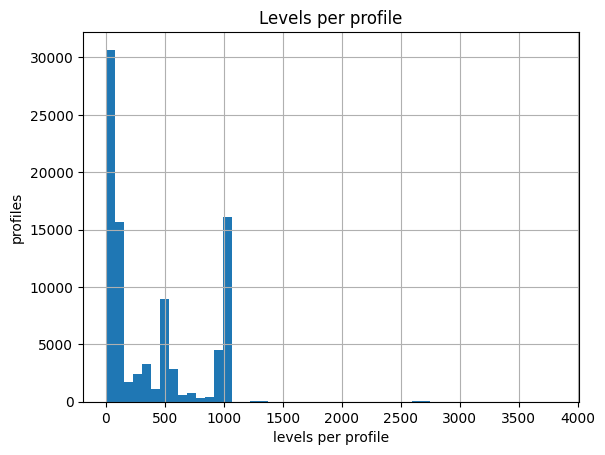

In [15]:
#how many levels does a typical profile have?

levels_pd = df.select("n_levels").toPandas()
print(levels_pd["n_levels"].describe())
levels_pd["n_levels"].hist(bins=50)
plt.xlabel("levels per profile"); plt.ylabel("profiles"); plt.title("Levels per profile")
plt.show()

In [32]:
#Exploding to level data on a SMALL sample first
#Choosing adjusted values for A/D data modes, raw values for R. Cast QC to int

adj = F.col("data_mode").isin("A", "D")
prepared = df.select(
    "profile_id", "dac", "ocean", "data_mode", "latitude", "longitude", "time",
    "position_qc", "juld_qc",
    *[F.when(adj, F.col(f"{v}_adjusted")).otherwise(F.col(v)).alias(v) for v in ("pres", "temp", "psal")],
    *[F.when(adj, F.col(f"{v}_adjusted_qc")).otherwise(F.col(f"{v}_qc")).alias(f"{v}_q") for v in ("pres", "temp", "psal")],
)

In [27]:
# Cast QC arrays to int (guards against string flags)

for v in ("pres", "temp", "psal"):
    prepared = prepared.withColumn(f"{v}_q", F.expr(f"transform({v}_q, x -> cast(x as int))"))

def explode_levels(frame):
    return frame.select(
        "profile_id", "dac", "ocean", "data_mode", "latitude", "longitude", "time",
        "position_qc", "juld_qc",
        F.expr("inline(arrays_zip(pres, pres_q, temp, temp_q, psal, psal_q))"))

sample_profiles = prepared.sample(False, 0.05, seed=42)      # about 5% of profiles
sample_levels = explode_levels(sample_profiles).cache()
print("sample level rows:", sample_levels.count())
sample_levels.show(5)

# Level-level quality: missingness and QC flags

for v in ("pres", "temp", "psal"):
    print(f"\n--- {v} ---")
    sample_levels.groupBy(f"{v}_q").count().orderBy(F.desc("count")).show()
sample_levels.select(
    *[F.avg(F.col(c).isNull().cast("int")).alias(f"null_rate_{c}") for c in ("pres", "temp", "psal")]
).show()

sample level rows: 1775782
+-----------+--------+-----+---------+--------+-------------------+-------------------+-----------+-------+----+------+-----+------+------+------+
| profile_id|     dac|ocean|data_mode|latitude|          longitude|               time|position_qc|juld_qc|pres|pres_q| temp|temp_q|  psal|psal_q|
+-----------+--------+-----+---------+--------+-------------------+-------------------+-----------+-------+----+------+-----+------+------+------+
|1900617_369|coriolis|    A|        D|  68.033|-13.171000000000001|2016-06-16 02:44:02|          1|      1|-0.7|     2|5.243|     1|34.717|     1|
|1900617_369|coriolis|    A|        D|  68.033|-13.171000000000001|2016-06-16 02:44:02|          1|      1| 4.0|     2|4.983|     1|34.714|     1|
|1900617_369|coriolis|    A|        D|  68.033|-13.171000000000001|2016-06-16 02:44:02|          1|      1| 9.1|     2|4.846|     1|34.684|     1|
|1900617_369|coriolis|    A|        D|  68.033|-13.171000000000001|2016-06-16 02:44:02|    

In [28]:
#Value ranges: raw vs good-only

good = sample_levels.where(
    F.col("temp_q").isin(1, 2) & F.col("psal_q").isin(1, 2) & F.col("pres_q").isin(1, 2))
print("share of levels kept after strict QC:",
      round(good.count() / sample_levels.count(), 4))
for label, frame in [("ALL levels", sample_levels), ("GOOD levels (QC 1,2)", good)]:
    print(label)
    frame.agg(F.min("temp"), F.max("temp"), F.avg("temp"),
              F.min("psal"), F.max("psal"), F.avg("psal"),
              F.min("pres"), F.max("pres")).show(truncate=False)

share of levels kept after strict QC: 0.9573
ALL levels
+---------+---------+-----------------+---------+---------+-----------------+---------+---------+
|min(temp)|max(temp)|avg(temp)        |min(psal)|max(psal)|avg(psal)        |min(pres)|max(pres)|
+---------+---------+-----------------+---------+---------+-----------------+---------+---------+
|-2.0     |46.688   |7.436490452447495|0.0      |67.242   |34.72870047247806|-116.4   |5502.5   |
+---------+---------+-----------------+---------+---------+-----------------+---------+---------+

GOOD levels (QC 1,2)
+---------+---------+-----------------+---------+---------+-----------------+---------+---------+
|min(temp)|max(temp)|avg(temp)        |min(psal)|max(psal)|avg(psal)        |min(pres)|max(pres)|
+---------+---------+-----------------+---------+---------+-----------------+---------+---------+
|-1.993   |31.751   |7.443989096117344|5.338    |40.564   |34.73102633644697|-0.7     |5502.5   |
+---------+---------+-----------------+-

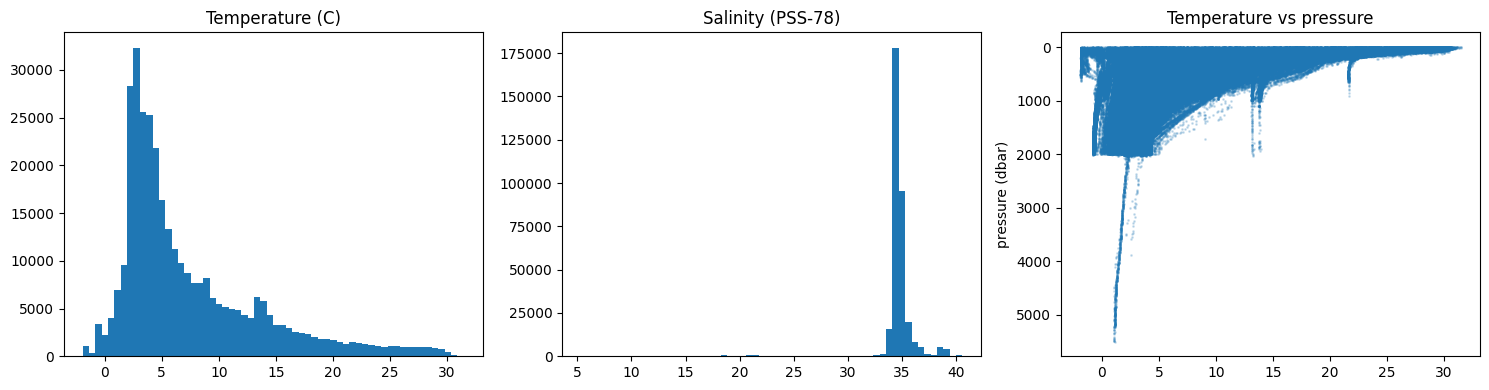

In [29]:
#Quick plots on good data

pdf = good.select("pres", "temp", "psal").sample(False, 0.2, seed=1).toPandas()
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].hist(pdf["temp"].dropna(), bins=60); ax[0].set_title("Temperature (C)")
ax[1].hist(pdf["psal"].dropna(), bins=60); ax[1].set_title("Salinity (PSS-78)")
ax[2].scatter(pdf["temp"], pdf["pres"], s=1, alpha=0.2)
ax[2].invert_yaxis(); ax[2].set_title("Temperature vs pressure"); ax[2].set_ylabel("pressure (dbar)")
plt.tight_layout(); plt.show()

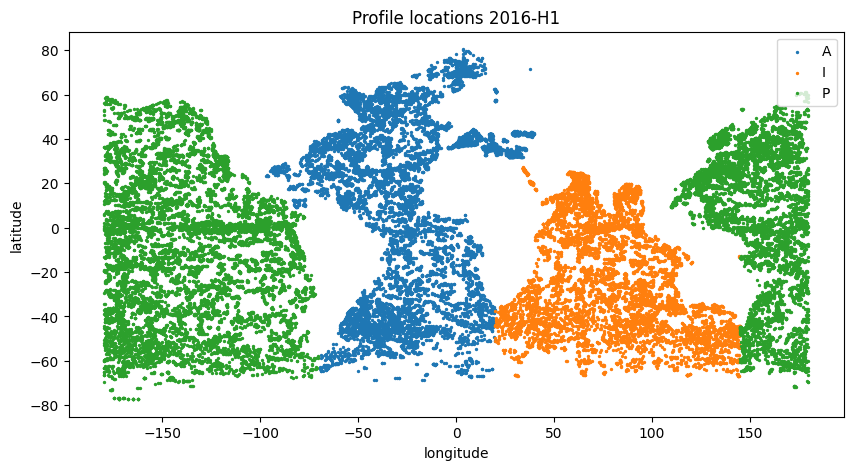

In [30]:
# Where do profiles occur

geo = (df.where(F.col("position_qc").isin("1", "2") & F.col("latitude").between(-90, 90)
                & F.col("longitude").between(-180, 180))
         .select("latitude", "longitude", "ocean").sample(False, 0.5, seed=3).toPandas())
plt.figure(figsize=(10, 5))
for o, g in geo.groupby("ocean"):
    plt.scatter(g["longitude"], g["latitude"], s=2, label=o)
plt.legend(); plt.xlabel("longitude"); plt.ylabel("latitude"); plt.title("Profile locations 2016-H1")
plt.show()
